# Fall Detection Threshold Finder

Load qpos trajectories from a generation rollout H5 file, render videos to visually identify falls,
then find a metric threshold (skull z-height) that reliably classifies fallen vs. upright.

In [1]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

import h5py
import numpy as np
import mujoco
import matplotlib.pyplot as plt
import mediapy as media
from pathlib import Path
from tqdm.notebook import tqdm
from PIL import Image, ImageDraw, ImageFont
from scamper.environment.rodent import consts as rodent_consts

## 1. Load H5 file and list datasets

In [2]:
h5_path = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_PULSE_fc_49.h5"
)
h5f = h5py.File(h5_path, "r")

# List all qpos datasets
qpos_datasets = {
    k: v for k, v in h5f.items() if k.endswith("_qpos") or k == "original_qpos"
}
print(f"H5 file: {h5_path.name}")
print(f"\nAvailable qpos datasets:")
for name, ds in sorted(qpos_datasets.items()):
    print(f"  {name}: {ds.shape}")

print(f"\nAttributes:")
for k, v in h5f.attrs.items():
    print(f"  {k}: {v}")

H5 file: generation_rollout_PULSE_fc_49.h5

Available qpos datasets:
  original_qpos: (842, 250, 74)
  prior_deterministic_qpos: (842, 490, 74)
  prior_logvar_-0.5_qpos: (842, 490, 74)
  prior_logvar_-1_qpos: (842, 490, 74)
  prior_logvar_-2_qpos: (842, 490, 74)
  prior_logvar_-3_qpos: (842, 490, 74)
  prior_logvar_-4_qpos: (842, 490, 74)
  prior_logvar_0_qpos: (842, 490, 74)
  prior_predicted_logvar_qpos: (842, 490, 74)
  student_encoder_decoder_qpos: (842, 490, 74)
  teacher_qpos: (842, 490, 74)

Attributes:
  checkpoint_path: /home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_checkpoints/260327_134740_079934
  intention_size: 16
  logvars: [-4.  -3.  -2.  -1.  -0.5  0. ]
  num_clips: 842
  num_steps: 490
  qpos_dim: 74


## 2. Build MuJoCo model and renderer

In [3]:
walker_xml = str(rodent_consts.RODENT_NO_TAIL_COLLISION_XML)
arena_xml = str(rodent_consts.ARENA_XML_PATH)

# Build combined arena+rodent model (matches the 74 DOF qpos from rollouts)
arena_spec = mujoco.MjSpec.from_file(arena_xml)
rodent_spec = mujoco.MjSpec.from_file(walker_xml)
frame = arena_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
spawn_body = frame.attach_body(rodent_spec.body("walker"), "", suffix="-rodent")
spawn_body.add_freejoint(name="root")
model = arena_spec.compile()
data = mujoco.MjData(model)

# Look up body IDs for fall detection
skull_body_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "skull-rodent")
torso_body_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "torso-rodent")
print(f"Model nq: {model.nq}")
print(f"skull-rodent body id: {skull_body_id}")
print(f"torso-rodent body id: {torso_body_id}")

render_height = 480
render_width = 640
camera = "close_profile-rodent"
renderer = mujoco.Renderer(model, height=render_height, width=render_width)
cam_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_CAMERA, camera)
print(f"Camera: {camera} (id={cam_id})")

Model nq: 74
skull-rodent body id: 56
torso-rodent body id: 3
Camera: close_profile-rodent (id=0)


## 3. Compute skull & torso z-height for a dataset

Run forward kinematics on every frame to get world-space body positions.

In [4]:
# Choose which dataset to analyze
dataset_name = "prior_logvar_-2_qpos"  # <-- CHANGE THIS to explore different datasets

qpos_data = h5f[dataset_name][:]
num_clips, num_steps, qpos_dim = qpos_data.shape
print(f"Dataset: {dataset_name}")
print(
    f"Shape: {qpos_data.shape} ({num_clips} clips, {num_steps} steps, {qpos_dim} DOF)"
)

Dataset: prior_logvar_-2_qpos
Shape: (842, 490, 74) (842 clips, 490 steps, 74 DOF)


In [5]:
# Compute skull z and torso z for all clips/steps via FK
# This takes a minute or so for 842 x 490
skull_z = np.zeros((num_clips, num_steps), dtype=np.float32)
torso_z = np.zeros((num_clips, num_steps), dtype=np.float32)

for clip_idx in tqdm(range(num_clips), desc="FK (skull+torso z)"):
    for step_idx in range(num_steps):
        data.qpos[:] = qpos_data[clip_idx, step_idx]
        mujoco.mj_forward(model, data)
        skull_z[clip_idx, step_idx] = data.xpos[skull_body_id, 2]
        torso_z[clip_idx, step_idx] = data.xpos[torso_body_id, 2]

print(f"Skull z range: [{skull_z.min():.4f}, {skull_z.max():.4f}]")
print(f"Torso z range: [{torso_z.min():.4f}, {torso_z.max():.4f}]")

FK (skull+torso z):   0%|          | 0/842 [00:00<?, ?it/s]

Skull z range: [-0.0053, 0.2346]
Torso z range: [0.0083, 0.1694]


## 4. Visualize z-height distributions to spot falls

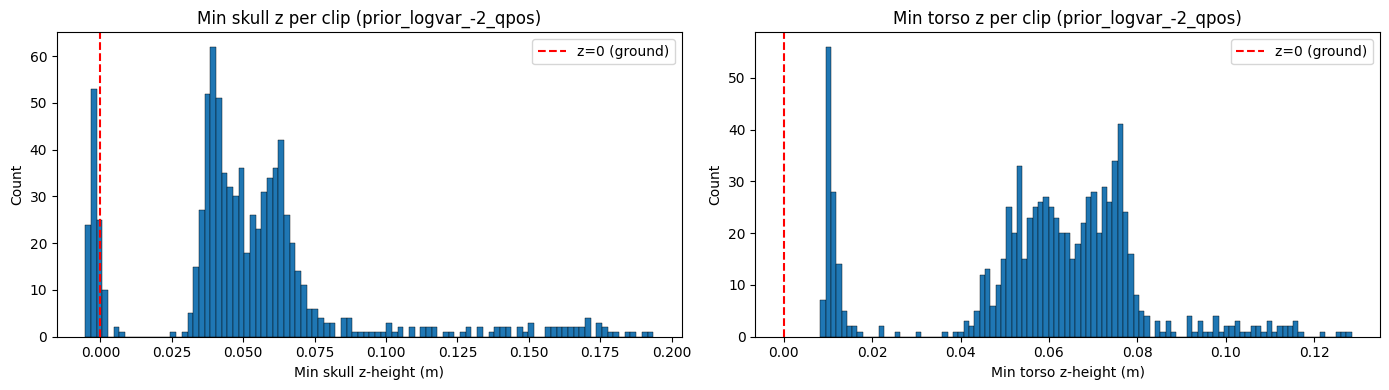

Clips with min skull z < 0: 93 / 842
Clips with min skull z < 0.01: 115 / 842
Clips with min skull z < 0.02: 115 / 842
Clips with min torso z < 0.03: 118 / 842


In [6]:
# Min skull z per clip (lowest point the skull reaches during the rollout)
min_skull_z = skull_z.min(axis=1)
min_torso_z = torso_z.min(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(min_skull_z, bins=100, edgecolor="black", linewidth=0.3)
axes[0].set_xlabel("Min skull z-height (m)")
axes[0].set_ylabel("Count")
axes[0].set_title(f"Min skull z per clip ({dataset_name})")
axes[0].axvline(0.0, color="red", linestyle="--", label="z=0 (ground)")
axes[0].legend()

axes[1].hist(min_torso_z, bins=100, edgecolor="black", linewidth=0.3)
axes[1].set_xlabel("Min torso z-height (m)")
axes[1].set_ylabel("Count")
axes[1].set_title(f"Min torso z per clip ({dataset_name})")
axes[1].axvline(0.0, color="red", linestyle="--", label="z=0 (ground)")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Clips with min skull z < 0: {(min_skull_z < 0).sum()} / {num_clips}")
print(f"Clips with min skull z < 0.01: {(min_skull_z < 0.01).sum()} / {num_clips}")
print(f"Clips with min skull z < 0.02: {(min_skull_z < 0.02).sum()} / {num_clips}")
print(f"Clips with min torso z < 0.03: {(min_torso_z < 0.03).sum()} / {num_clips}")

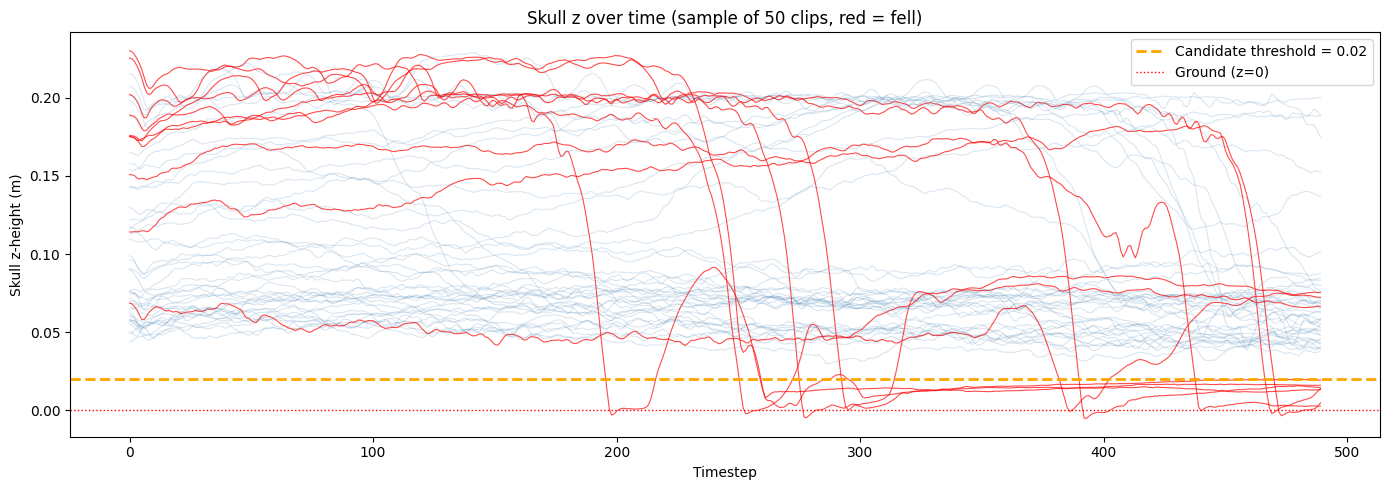

With threshold 0.02: 115/842 clips classified as fallen (13.7%)


In [8]:
# Skull z over time for a random sample of clips
# Color by whether the clip likely fell (min skull z below a candidate threshold)
candidate_threshold = 0.02  # <-- ADJUST THIS

rng = np.random.default_rng(42)
sample_size = 50
sample_indices = rng.choice(num_clips, size=min(sample_size, num_clips), replace=False)

fig, ax = plt.subplots(figsize=(14, 5))
timesteps = np.arange(num_steps)

for idx in sample_indices:
    fell = min_skull_z[idx] < candidate_threshold
    color = "red" if fell else "steelblue"
    alpha = 0.7 if fell else 0.2
    ax.plot(timesteps, skull_z[idx], color=color, alpha=alpha, linewidth=0.8)

ax.axhline(
    candidate_threshold,
    color="orange",
    linestyle="--",
    linewidth=2,
    label=f"Candidate threshold = {candidate_threshold}",
)
ax.axhline(0.0, color="red", linestyle=":", linewidth=1, label="Ground (z=0)")
ax.set_xlabel("Timestep")
ax.set_ylabel("Skull z-height (m)")
ax.set_title(f"Skull z over time (sample of {sample_size} clips, red = fell)")
ax.legend()
plt.tight_layout()
plt.show()

n_fell = (min_skull_z < candidate_threshold).sum()
print(
    f"With threshold {candidate_threshold}: {n_fell}/{num_clips} clips classified as fallen ({100*n_fell/num_clips:.1f}%)"
)

## 5. Render videos of specific clips to validate

Sort clips by min skull z and render the ones near the boundary to verify the threshold.

In [9]:
# Sort clips by min skull z — lowest first (most clearly fallen)
sorted_by_skull_z = np.argsort(min_skull_z)

print("Clips sorted by min skull z (lowest first):")
print(f"{'Rank':<6} {'Clip':<8} {'Min skull z':<14} {'Min torso z':<14}")
print("-" * 42)
for rank in range(20):
    idx = sorted_by_skull_z[rank]
    print(f"{rank:<6} {idx:<8} {min_skull_z[idx]:<14.4f} {min_torso_z[idx]:<14.4f}")

Clips sorted by min skull z (lowest first):
Rank   Clip     Min skull z    Min torso z   
------------------------------------------
0      754      -0.0053        0.0102        
1      284      -0.0052        0.0103        
2      296      -0.0051        0.0107        
3      572      -0.0047        0.0096        
4      635      -0.0046        0.0096        
5      641      -0.0046        0.0109        
6      827      -0.0044        0.0090        
7      794      -0.0043        0.0100        
8      397      -0.0041        0.0107        
9      302      -0.0041        0.0106        
10     555      -0.0041        0.0124        
11     104      -0.0040        0.0104        
12     124      -0.0039        0.0096        
13     765      -0.0039        0.0108        
14     285      -0.0039        0.0106        
15     218      -0.0039        0.0108        
16     553      -0.0038        0.0097        
17     692      -0.0038        0.0113        
18     434      -0.0037        0.0107  

In [10]:
def render_clip_video(qpos_clip, fps=50):
    """Render a qpos trajectory as a video with frame labels."""
    try:
        font = ImageFont.truetype(
            "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 24
        )
    except OSError:
        font = ImageFont.load_default(size=24)

    frames = []
    for t in range(len(qpos_clip)):
        data.qpos[:] = np.array(qpos_clip[t])
        mujoco.mj_forward(model, data)
        renderer.update_scene(data, camera=cam_id)
        frame = renderer.render().copy()

        img = Image.fromarray(frame)
        draw = ImageDraw.Draw(img)
        draw.text((10, 10), f"t={t}", fill=(255, 255, 255), font=font)
        frames.append(np.array(img))

    return frames

In [11]:
# Render N clips: pick from the clearly-fallen end
num_to_render = 3  # <-- how many to render
render_start_rank = (
    0  # <-- start from rank 0 (worst falls), increase to see milder cases
)

for rank in range(render_start_rank, render_start_rank + num_to_render):
    clip_idx = sorted_by_skull_z[rank]
    print(
        f"\n--- Rank {rank}: clip {clip_idx}, min skull z = {min_skull_z[clip_idx]:.4f} ---"
    )
    frames = render_clip_video(qpos_data[clip_idx])
    media.show_video(frames, fps=50)


--- Rank 0: clip 754, min skull z = -0.0053 ---


This browser does not support the video tag.



--- Rank 1: clip 284, min skull z = -0.0052 ---


This browser does not support the video tag.



--- Rank 2: clip 296, min skull z = -0.0051 ---


This browser does not support the video tag.


In [12]:
# Render clips near the threshold boundary to calibrate
# Find clips whose min skull z is closest to the candidate threshold
distance_to_threshold = np.abs(min_skull_z - candidate_threshold)
boundary_clips = np.argsort(distance_to_threshold)

num_boundary = 4  # <-- how many boundary clips to render

print(f"Clips nearest to threshold {candidate_threshold}:")
for i in range(num_boundary):
    clip_idx = boundary_clips[i]
    fell = "FELL" if min_skull_z[clip_idx] < candidate_threshold else "OK"
    print(f"  Clip {clip_idx}: min skull z = {min_skull_z[clip_idx]:.4f} [{fell}]")

for i in range(num_boundary):
    clip_idx = boundary_clips[i]
    fell = "FELL" if min_skull_z[clip_idx] < candidate_threshold else "OK"
    print(
        f"\n--- Clip {clip_idx}, min skull z = {min_skull_z[clip_idx]:.4f} [{fell}] ---"
    )
    frames = render_clip_video(qpos_data[clip_idx])
    media.show_video(frames, fps=50)

Clips nearest to threshold 0.02:
  Clip 378: min skull z = 0.0260 [OK]
  Clip 406: min skull z = 0.0297 [OK]
  Clip 426: min skull z = 0.0307 [OK]
  Clip 100: min skull z = 0.0313 [OK]

--- Clip 378, min skull z = 0.0260 [OK] ---


This browser does not support the video tag.



--- Clip 406, min skull z = 0.0297 [OK] ---


This browser does not support the video tag.



--- Clip 426, min skull z = 0.0307 [OK] ---


This browser does not support the video tag.



--- Clip 100, min skull z = 0.0313 [OK] ---


This browser does not support the video tag.


## 6. Skull z + torso z time series for boundary clips

Plot the z-height over time for clips near the threshold, so you can see exactly when the fall happens.

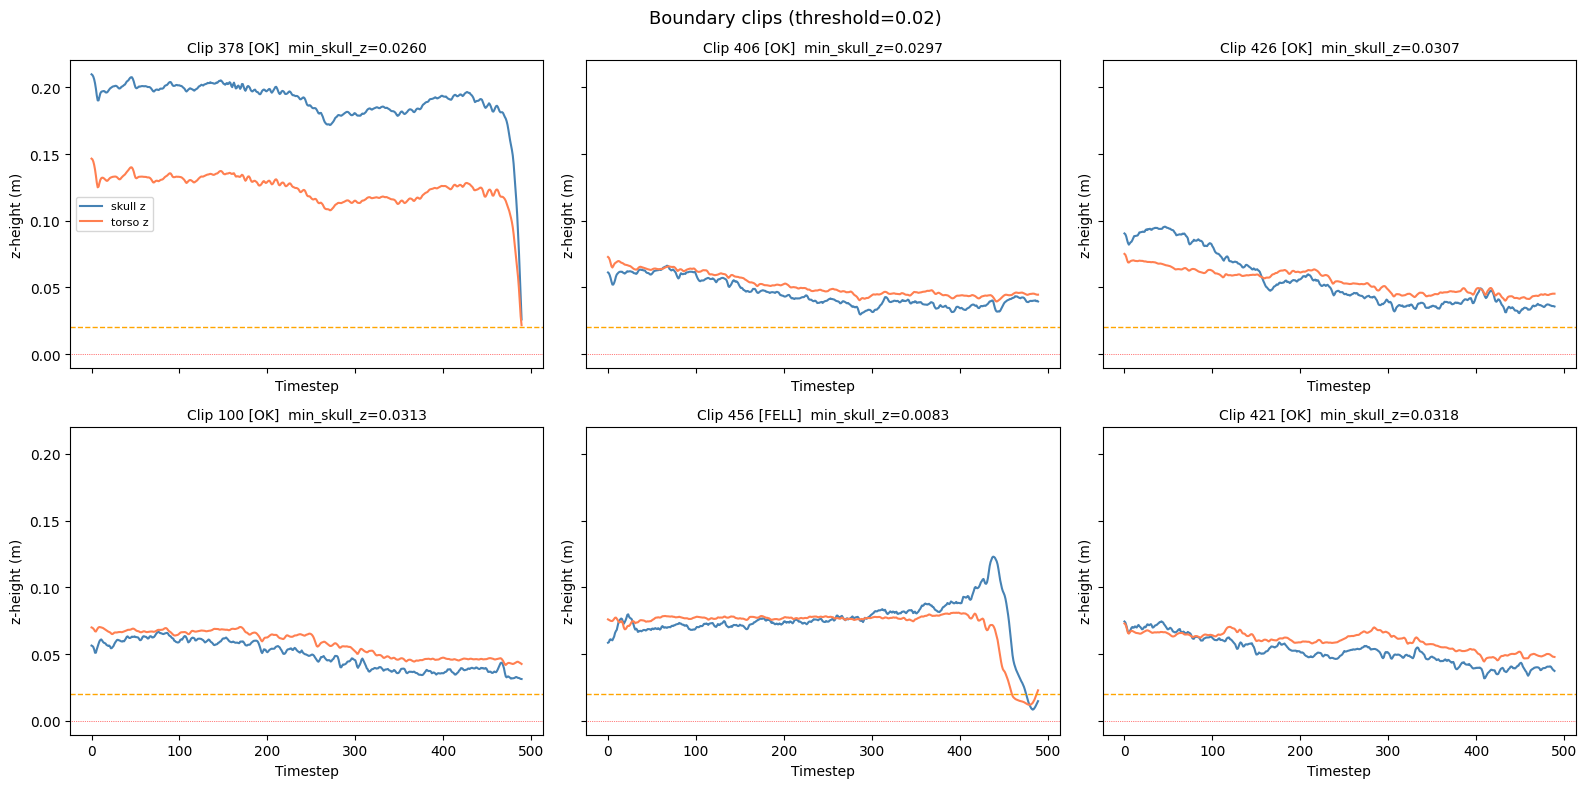

In [13]:
num_to_plot = 6
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True, sharey=True)

for i, ax in enumerate(axes.flat):
    if i >= num_to_plot:
        ax.set_visible(False)
        continue
    clip_idx = boundary_clips[i]
    fell = "FELL" if min_skull_z[clip_idx] < candidate_threshold else "OK"
    ax.plot(timesteps, skull_z[clip_idx], label="skull z", color="steelblue")
    ax.plot(timesteps, torso_z[clip_idx], label="torso z", color="coral")
    ax.axhline(candidate_threshold, color="orange", linestyle="--", linewidth=1)
    ax.axhline(0.0, color="red", linestyle=":", linewidth=0.5)
    ax.set_title(
        f"Clip {clip_idx} [{fell}]  min_skull_z={min_skull_z[clip_idx]:.4f}",
        fontsize=10,
    )
    ax.set_xlabel("Timestep")
    ax.set_ylabel("z-height (m)")
    if i == 0:
        ax.legend(fontsize=8)

plt.suptitle(f"Boundary clips (threshold={candidate_threshold})", fontsize=13)
plt.tight_layout()
plt.show()

## 7. Sweep thresholds and plot fallen fraction per dataset

Compare how many clips are classified as fallen across different thresholds and datasets.

In [14]:
# Compute min skull z for ALL qpos datasets (takes a while)
all_min_skull_z = {}

for ds_name in sorted(qpos_datasets.keys()):
    if ds_name == "original_qpos":
        continue  # skip reference (different num_steps)
    ds = h5f[ds_name][:]
    nc, ns, _ = ds.shape
    sz = np.zeros((nc, ns), dtype=np.float32)
    for clip_idx in tqdm(range(nc), desc=ds_name, leave=False):
        for step_idx in range(ns):
            data.qpos[:] = ds[clip_idx, step_idx]
            mujoco.mj_forward(model, data)
            sz[clip_idx, step_idx] = data.xpos[skull_body_id, 2]
    all_min_skull_z[ds_name] = sz.min(axis=1)
    n_below_zero = (sz.min(axis=1) < 0).sum()
    print(f"  {ds_name}: {n_below_zero}/{nc} below z=0")

prior_deterministic_qpos:   0%|          | 0/842 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# Sweep thresholds
thresholds = np.linspace(-0.01, 0.06, 200)

fig, ax = plt.subplots(figsize=(12, 6))

for ds_name in sorted(all_min_skull_z.keys()):
    min_sz = all_min_skull_z[ds_name]
    fractions = [(min_sz < t).sum() / len(min_sz) for t in thresholds]
    ax.plot(thresholds, fractions, label=ds_name.replace("_qpos", ""), linewidth=1.5)

ax.set_xlabel("Skull z threshold (m)")
ax.set_ylabel("Fraction of clips classified as fallen")
ax.set_title("Fallen fraction vs. skull z threshold")
ax.legend(fontsize=8, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Final threshold selection

Set your chosen threshold and see the final stats.

In [15]:
# ===== SET YOUR FINAL THRESHOLD HERE =====
FALL_THRESHOLD = 0.02  # skull z below this = fallen
# ==========================================

print(f"Fall threshold: skull z < {FALL_THRESHOLD} m")
print(f"{'Dataset':<40} {'Fallen':<10} {'Total':<10} {'%':<8}")
print("-" * 68)

for ds_name in sorted(all_min_skull_z.keys()):
    min_sz = all_min_skull_z[ds_name]
    n_fell = (min_sz < FALL_THRESHOLD).sum()
    n_total = len(min_sz)
    pct = 100 * n_fell / n_total
    print(f"{ds_name:<40} {n_fell:<10} {n_total:<10} {pct:<8.1f}")

Fall threshold: skull z < 0.02 m
Dataset                                  Fallen     Total      %       
--------------------------------------------------------------------


Dataset: prior_logvar_-2_qpos
Fallen clips: 115/842
Fall step stats (for fallen clips):
  Mean: 320
  Median: 329
  Min: 39
  Max: 476


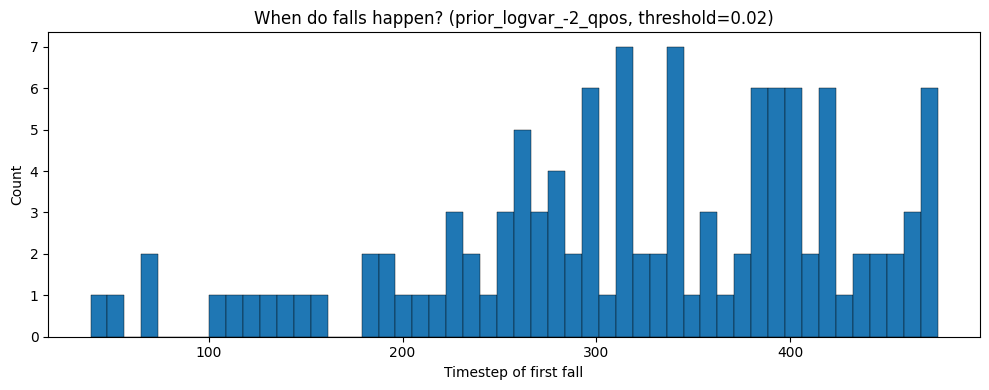

In [16]:
# Detect the first timestep where the fall occurs for each clip
# (useful for knowing how long the agent stays upright)
ds_name_for_fall_step = dataset_name  # uses the dataset loaded in section 3

fall_step = np.full(num_clips, num_steps, dtype=int)  # default: never fell
for clip_idx in range(num_clips):
    below = np.where(skull_z[clip_idx] < FALL_THRESHOLD)[0]
    if len(below) > 0:
        fall_step[clip_idx] = below[0]

fell_mask = fall_step < num_steps
print(f"Dataset: {ds_name_for_fall_step}")
print(f"Fallen clips: {fell_mask.sum()}/{num_clips}")
if fell_mask.sum() > 0:
    print(f"Fall step stats (for fallen clips):")
    print(f"  Mean: {fall_step[fell_mask].mean():.0f}")
    print(f"  Median: {np.median(fall_step[fell_mask]):.0f}")
    print(f"  Min: {fall_step[fell_mask].min()}")
    print(f"  Max: {fall_step[fell_mask].max()}")

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(fall_step[fell_mask], bins=50, edgecolor="black", linewidth=0.3)
    ax.set_xlabel("Timestep of first fall")
    ax.set_ylabel("Count")
    ax.set_title(
        f"When do falls happen? ({ds_name_for_fall_step}, threshold={FALL_THRESHOLD})"
    )
    plt.tight_layout()
    plt.show()

In [ ]:
h5f.close()

## 9. Survival curves: Prior (PULSE) vs. RGM across noise levels

Load both H5 files, compute skull z via FK for every dataset, then plot Kaplan-Meier–style survival curves (fraction of clips still upright at each timestep).

In [17]:
# ===== Configuration =====
FALL_THRESHOLD = 0.02  # skull z below this = fallen (tune in sections above)

pulse_h5_path = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_PULSE_fc_49.h5"
rgm_h5_path = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_rgm_54.h5"

pulse_h5 = h5py.File(pulse_h5_path, "r")
rgm_h5 = h5py.File(rgm_h5_path, "r")

print("PULSE datasets:")
for k in sorted(pulse_h5.keys()):
    if k.endswith("_qpos") and k != "original_qpos":
        print(f"  {k}: {pulse_h5[k].shape}")

print("\nRGM datasets:")
for k in sorted(rgm_h5.keys()):
    if k.endswith("_qpos") and k != "original_qpos":
        print(f"  {k}: {rgm_h5[k].shape}")

PULSE datasets:
  prior_deterministic_qpos: (842, 490, 74)
  prior_logvar_-0.5_qpos: (842, 490, 74)
  prior_logvar_-1_qpos: (842, 490, 74)
  prior_logvar_-2_qpos: (842, 490, 74)
  prior_logvar_-3_qpos: (842, 490, 74)
  prior_logvar_-4_qpos: (842, 490, 74)
  prior_logvar_0_qpos: (842, 490, 74)
  prior_predicted_logvar_qpos: (842, 490, 74)
  student_encoder_decoder_qpos: (842, 490, 74)
  teacher_qpos: (842, 490, 74)

RGM datasets:
  rgm_deterministic_qpos: (842, 490, 74)
  rgm_logvar_-0.5_qpos: (842, 490, 74)
  rgm_logvar_-1_qpos: (842, 490, 74)
  rgm_logvar_-2_qpos: (842, 490, 74)
  rgm_logvar_-3_qpos: (842, 490, 74)
  rgm_logvar_-4_qpos: (842, 490, 74)
  rgm_logvar_0_qpos: (842, 490, 74)
  rgm_predicted_logvar_qpos: (842, 490, 74)
  student_encoder_decoder_qpos: (842, 490, 74)


In [18]:
def compute_skull_z_for_h5(h5f, model, data, skull_body_id):
    """Compute skull z for every qpos dataset in an H5 file.

    Returns dict mapping dataset name -> skull_z array (num_clips, num_steps).
    """
    results = {}
    ds_names = [
        k for k in sorted(h5f.keys()) if k.endswith("_qpos") and k != "original_qpos"
    ]

    for ds_name in ds_names:
        qpos = h5f[ds_name][:]
        nc, ns, _ = qpos.shape
        sz = np.zeros((nc, ns), dtype=np.float32)
        for clip_idx in tqdm(range(nc), desc=ds_name, leave=False):
            for step_idx in range(ns):
                data.qpos[:] = qpos[clip_idx, step_idx]
                mujoco.mj_forward(model, data)
                sz[clip_idx, step_idx] = data.xpos[skull_body_id, 2]
        results[ds_name] = sz
        n_fell = (sz.min(axis=1) < FALL_THRESHOLD).sum()
        print(f"  {ds_name}: {n_fell}/{nc} fallen (threshold={FALL_THRESHOLD})")

    return results


def compute_survival_curves(skull_z_dict, threshold):
    """Compute survival curves from skull z arrays.

    Returns dict mapping dataset name -> survival array of shape (num_steps,),
    where survival[t] = fraction of clips with skull z >= threshold for all steps <= t.
    """
    curves = {}
    for ds_name, sz in skull_z_dict.items():
        nc, ns = sz.shape
        # Once skull z drops below threshold, clip counts as fallen from then on
        fell_below = sz < threshold
        ever_fallen = np.maximum.accumulate(fell_below, axis=1)
        # Survival at each timestep = fraction NOT yet fallen
        curves[ds_name] = 1.0 - ever_fallen.mean(axis=0)
    return curves

In [19]:
# Compute skull z for all datasets in both files (this takes a while)
print("Computing skull z for PULSE (prior) datasets...")
pulse_skull_z = compute_skull_z_for_h5(pulse_h5, model, data, skull_body_id)

print("\nComputing skull z for RGM datasets...")
rgm_skull_z = compute_skull_z_for_h5(rgm_h5, model, data, skull_body_id)

Computing skull z for PULSE (prior) datasets...


prior_deterministic_qpos:   0%|          | 0/842 [00:00<?, ?it/s]

  prior_deterministic_qpos: 171/842 fallen (threshold=0.02)


prior_logvar_-0.5_qpos:   0%|          | 0/842 [00:00<?, ?it/s]

  prior_logvar_-0.5_qpos: 145/842 fallen (threshold=0.02)


...

  rgm_logvar_0_qpos: 594/842 fallen (threshold=0.02)


rgm_predicted_logvar_qpos:   0%|          | 0/842 [00:00<?, ?it/s]

  rgm_predicted_logvar_qpos: 77/842 fallen (threshold=0.02)


student_encoder_decoder_qpos:   0%|          | 0/842 [00:00<?, ?it/s]

  student_encoder_decoder_qpos: 19/842 fallen (threshold=0.02)


In [ ]:
# Compute survival curves
pulse_survival = compute_survival_curves(pulse_skull_z, FALL_THRESHOLD)
rgm_survival = compute_survival_curves(rgm_skull_z, FALL_THRESHOLD)

# Get num_steps from any dataset
ns = next(iter(pulse_skull_z.values())).shape[1]
timesteps = np.arange(ns)
time_seconds = timesteps * 0.02  # ctrl_dt = 0.01, but 2 sim steps per ctrl step -> 50Hz

### Matching noise levels between Prior (PULSE) and RGM

Map `prior_*` datasets to `rgm_*` datasets at the same noise level and plot side-by-side.

In [ ]:
# Build matched pairs: (label, pulse_key, rgm_key)
# Noise levels present in both files
matched_pairs = [
    ("deterministic", "prior_deterministic_qpos", "rgm_deterministic_qpos"),
    ("logvar=-4", "prior_logvar_-4_qpos", "rgm_logvar_-4_qpos"),
    ("logvar=-3", "prior_logvar_-3_qpos", "rgm_logvar_-3_qpos"),
    ("logvar=-2", "prior_logvar_-2_qpos", "rgm_logvar_-2_qpos"),
    ("logvar=-1", "prior_logvar_-1_qpos", "rgm_logvar_-1_qpos"),
    ("logvar=-0.5", "prior_logvar_-0.5_qpos", "rgm_logvar_-0.5_qpos"),
    ("logvar=0", "prior_logvar_0_qpos", "rgm_logvar_0_qpos"),
    ("predicted logvar", "prior_predicted_logvar_qpos", "rgm_predicted_logvar_qpos"),
]

# Also include shared datasets
shared_keys = []
if "student_encoder_decoder_qpos" in pulse_survival:
    shared_keys.append(
        ("student enc-dec (PULSE)", "student_encoder_decoder_qpos", "pulse")
    )
if "teacher_qpos" in pulse_survival:
    shared_keys.append(("teacher (PULSE)", "teacher_qpos", "pulse"))
if "student_encoder_decoder_qpos" in rgm_survival:
    shared_keys.append(("student enc-dec (RGM)", "student_encoder_decoder_qpos", "rgm"))

print(f"Matched noise levels: {len(matched_pairs)}")
print(f"Shared datasets: {len(shared_keys)}")

In [ ]:
# ---- Plot 1: All survival curves, one subplot per noise level ----
n_pairs = len(matched_pairs)
ncols = 4
nrows = (n_pairs + ncols - 1) // ncols
fig, axes = plt.subplots(
    nrows, ncols, figsize=(5 * ncols, 4 * nrows), sharex=True, sharey=True
)
axes = axes.flat

for i, (label, p_key, r_key) in enumerate(matched_pairs):
    ax = axes[i]
    if p_key in pulse_survival:
        ax.plot(
            time_seconds,
            pulse_survival[p_key],
            label="Prior (PULSE)",
            color="tab:blue",
            linewidth=1.5,
        )
    if r_key in rgm_survival:
        ax.plot(
            time_seconds,
            rgm_survival[r_key],
            label="RGM",
            color="tab:orange",
            linewidth=1.5,
        )
    ax.set_title(label, fontsize=11)
    ax.set_ylim(-0.02, 1.02)
    ax.grid(True, alpha=0.3)
    if i == 0:
        ax.legend(fontsize=8)

# Hide unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.supxlabel("Time (s)", fontsize=12)
fig.supylabel(
    "Fraction surviving (skull z >= {:.3f})".format(FALL_THRESHOLD), fontsize=12
)
fig.suptitle(
    f"Survival curves: Prior (PULSE) vs RGM  |  threshold = {FALL_THRESHOLD}",
    fontsize=14,
)
plt.tight_layout()
plt.show()

In [ ]:
# ---- Plot 2: All noise levels overlaid, one panel per model ----
fig, (ax_pulse, ax_rgm) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

cmap = plt.cm.viridis
n_levels = len(matched_pairs)

for i, (label, p_key, r_key) in enumerate(matched_pairs):
    color = cmap(i / (n_levels - 1))
    if p_key in pulse_survival:
        ax_pulse.plot(
            time_seconds, pulse_survival[p_key], label=label, color=color, linewidth=1.5
        )
    if r_key in rgm_survival:
        ax_rgm.plot(
            time_seconds, rgm_survival[r_key], label=label, color=color, linewidth=1.5
        )

# Add shared baselines
for label, key, source in shared_keys:
    curve = pulse_survival[key] if source == "pulse" else rgm_survival[key]
    ax_pulse.plot(
        time_seconds,
        curve,
        label=label,
        color="black",
        linestyle="--",
        linewidth=1.5,
        alpha=0.7,
    )
    ax_rgm.plot(
        time_seconds,
        curve,
        label=label,
        color="black",
        linestyle="--",
        linewidth=1.5,
        alpha=0.7,
    )

for ax, title in [(ax_pulse, "Prior (PULSE)"), (ax_rgm, "RGM")]:
    ax.set_xlabel("Time (s)")
    ax.set_title(title, fontsize=13)
    ax.set_ylim(-0.02, 1.02)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc="lower left")

ax_pulse.set_ylabel("Fraction surviving")
fig.suptitle(
    f"Survival curves across noise levels  |  threshold = {FALL_THRESHOLD}", fontsize=14
)
plt.tight_layout()
plt.show()

In [ ]:
# ---- Plot 3: Direct comparison — same noise level, both models overlaid ----
fig, ax = plt.subplots(figsize=(12, 6))

for i, (label, p_key, r_key) in enumerate(matched_pairs):
    color = cmap(i / (n_levels - 1))
    if p_key in pulse_survival:
        ax.plot(
            time_seconds,
            pulse_survival[p_key],
            color=color,
            linewidth=1.5,
            linestyle="-",
            label=f"Prior: {label}",
        )
    if r_key in rgm_survival:
        ax.plot(
            time_seconds,
            rgm_survival[r_key],
            color=color,
            linewidth=1.5,
            linestyle="--",
            label=f"RGM: {label}",
        )

ax.set_xlabel("Time (s)")
ax.set_ylabel("Fraction surviving")
ax.set_title(
    f"Prior (PULSE) vs RGM survival  |  solid=Prior, dashed=RGM  |  threshold={FALL_THRESHOLD}"
)
ax.set_ylim(-0.02, 1.02)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=7, ncol=2, loc="lower left")
plt.tight_layout()
plt.show()

In [ ]:
# ---- Summary table: final survival rate at last timestep ----
print(f"Final survival rate at t={time_seconds[-1]:.1f}s (threshold={FALL_THRESHOLD})")
print(f"{'Noise level':<20} {'Prior (PULSE)':<16} {'RGM':<16} {'Diff (RGM-Prior)':<16}")
print("-" * 68)

for label, p_key, r_key in matched_pairs:
    p_surv = pulse_survival.get(p_key, np.array([np.nan]))[-1]
    r_surv = rgm_survival.get(r_key, np.array([np.nan]))[-1]
    diff = r_surv - p_surv
    print(f"{label:<20} {p_surv:<16.3f} {r_surv:<16.3f} {diff:+.3f}")

print()
for label, key, source in shared_keys:
    curve = pulse_survival[key] if source == "pulse" else rgm_survival[key]
    print(f"{label:<20} {curve[-1]:.3f}")

In [ ]:
pulse_h5.close()
rgm_h5.close()